# Yokoi SSV Pro Workflow

## Why this Pro branch exists

This notebook preserves the strict legacy R reproduction unchanged while running a robustness-corrected Pro workflow. It addresses stochastic direction imbalance, batch-size balancing without class-prevalence control, raw-error sensitivity to prevalence shift, and per-split resampling of the retained cohort.


# Yokoi analysis with the Python SSV workflow

This notebook starts the Yokoi-specific SSV analysis path and covers Block 1 only: setup, controls, loading the Yokoi combined metadata/expression file, and checking sample alignment.

The Yokoi-specific R source for cross-checking is `SSV Yokoi.Rmd` in this workspace. Earlier prompts referred to `SSV Yokoi(2).Rmd`; that duplicate-upload suffix is ignored here.


## Setup and experiment controls


In [3]:
from pathlib import Path
import pandas as pd

try:
    from IPython.display import display
except ImportError:
    def display(value):
        print(value)
        
DATA_PATH = Path("combined_metadata_expression_GSE106817.csv")
META_PATH = Path("Yokoi_meta.csv")

OUTPUT_DIR = DATA_PATH.parent
YOKOI_STRUCTURE_SEED = 12345
TIMES = 10
BATCH_TIME = False
BATCH_BALANCE = True
SPLIT_COMBINATION = (50, 70, 80, 90, 100)
DATA_TYPE_RNASEQ = False
NORMALIZATION_METHODS = ("non", "qn", "mn", "vsn")
CLASSIFIER_METHODS = ("knn", "lasso", "rf", "svm", "xgb")
assert DATA_PATH.exists(), f"Missing Yokoi combined data file: {DATA_PATH}"
assert META_PATH.exists(), f"Missing Yokoi metadata cross-check file: {META_PATH}"

## Load and align Yokoi data


In [4]:
def make_unique_like_r(values):
    """Return names with R make.unique-style numeric suffixes for duplicates."""
    seen = {}
    unique_values = []
    for value in map(str, values):
        count = seen.get(value, 0)
        unique_values.append(value if count == 0 else f"{value}.{count}")
        seen[value] = count + 1
    return unique_values


def load_yokoi_combined_csv(path):
    """Load the Yokoi combined metadata/expression CSV using Block 1 semantics."""
    combined = pd.read_csv(path, dtype=str)
    if combined.shape[0] <= 8:
        raise ValueError("combined data must contain 8 metadata rows plus expression rows")
    if combined.shape[1] <= 1:
        raise ValueError("combined data must contain one ID column and at least one sample column")

    sample_ids = pd.Index(combined.columns[1:].astype(str), name="sample_id")
    if not sample_ids.is_unique:
        raise ValueError("sample IDs in the combined file are not unique")

    metadata_rows = combined.iloc[:8, :]
    metadata_field_names = make_unique_like_r(metadata_rows.iloc[:, 0])
    metadata = metadata_rows.iloc[:, 1:].T.copy(deep=True)
    metadata.index = sample_ids
    metadata.index.name = "sample_id"
    metadata.columns = metadata_field_names

    class_labels_raw = metadata_rows.iloc[4, 1:].copy(deep=True)
    class_labels_raw.index = sample_ids
    class_labels_raw.name = "class_label_raw"

    expression_rows = combined.iloc[8:, :]
    feature_ids = pd.Index(make_unique_like_r(expression_rows.iloc[:, 0]), name="feature_id")
    if feature_ids.empty:
        raise ValueError("expression matrix has no feature rows")
    if not feature_ids.is_unique:
        raise ValueError("feature IDs are not unique after make_unique-style repair")

    expression_values = expression_rows.iloc[:, 1:].apply(pd.to_numeric, errors="raise")
    expression_all = pd.DataFrame(
        expression_values.to_numpy(copy=True),
        index=feature_ids,
        columns=sample_ids,
    )

    return expression_all, metadata, class_labels_raw


def load_yokoi_meta_crosscheck(path, expected_sample_ids):
    """Read Yokoi_meta.csv only as a sample-order cross-check."""
    meta_crosscheck = pd.read_csv(path, dtype=str)
    if "sample_id" not in meta_crosscheck.columns:
        raise ValueError("Yokoi_meta.csv must contain a sample_id column for cross-checking")

    meta_sample_ids = pd.Index(meta_crosscheck["sample_id"].astype(str), name="sample_id")
    if not meta_sample_ids.is_unique:
        raise ValueError("sample_id values in Yokoi_meta.csv are not unique")
    if not expected_sample_ids.equals(meta_sample_ids):
        raise ValueError("Yokoi_meta.csv sample_id values do not match combined-file sample order")

    return meta_crosscheck.set_index("sample_id", drop=False)


def validate_yokoi_block1(expression_all, metadata, class_labels_raw):
    """Validate Block 1 sample alignment without altering the source data."""
    if expression_all.empty:
        raise ValueError("expression matrix is empty")
    if metadata.empty:
        raise ValueError("metadata table is empty")
    if class_labels_raw.empty:
        raise ValueError("class label vector is empty")
    if not expression_all.columns.equals(metadata.index):
        raise ValueError("expression columns and metadata sample IDs are not identically aligned")
    if not expression_all.columns.equals(class_labels_raw.index):
        raise ValueError("expression columns and class-label sample IDs are not identically aligned")
    if not expression_all.columns.is_unique:
        raise ValueError("expression sample IDs are not unique")
    if not expression_all.index.is_unique:
        raise ValueError("expression feature IDs are not unique")
    if not all(pd.api.types.is_numeric_dtype(dtype) for dtype in expression_all.dtypes):
        raise TypeError("all expression columns must be numeric")

    return {
        "n_features": expression_all.shape[0],
        "n_samples": expression_all.shape[1],
        "n_metadata_fields": metadata.shape[1],
        "n_classes": class_labels_raw.nunique(dropna=False),
    }


In [5]:
expression_all, metadata, class_labels_raw = load_yokoi_combined_csv(DATA_PATH)
yokoi_meta_crosscheck = load_yokoi_meta_crosscheck(META_PATH, expression_all.columns)
load_summary = validate_yokoi_block1(expression_all, metadata, class_labels_raw)

print("Yokoi Block 1 data loaded and aligned.")
print(f"Expression: {load_summary['n_features']} features x {load_summary['n_samples']} samples")
print(f"Metadata: {load_summary['n_samples']} samples x {load_summary['n_metadata_fields']} fields")
print(f"Raw class labels: {load_summary['n_classes']} classes")
print("Yokoi_meta.csv sample_id order matches the combined file.")

display(class_labels_raw.value_counts(dropna=False).rename_axis("class_label_raw").to_frame("n_samples"))


Yokoi Block 1 data loaded and aligned.
Expression: 2565 features x 4046 samples
Metadata: 4046 samples x 8 fields
Raw class labels: 13 classes
Yokoi_meta.csv sample_id order matches the combined file.


,n_samples
class_label_raw,
non-Cancer,2759
Ovarian Cancer,320
Breast Cancer,115
Colorectal Cancer,115
Gastric Cancer,115
Lung Cancer,115
Pancreatic Cancer,115
Sarcoma,115
Esophageal Cancer,88


## Frozen Batch Labels


In [6]:
FROZEN_BATCH_DIR = Path("frozen_batches")
FROZEN_BATCH_DIR.mkdir(exist_ok=True)


def load_frozen_batches(scenario_name, expected_sample_ids):
    path = FROZEN_BATCH_DIR / f"{scenario_name}_inferred_batches.csv"
    if not path.exists():
        raise FileNotFoundError(
            f"Missing frozen batch file: {path}. Create it once from validated R-reproduction batch labels. "
            "The Pro notebook intentionally does not rerun UMAP/KMeans."
        )
    frame = pd.read_csv(path)
    required = {"sample_id", "inferred_batch"}
    missing = required - set(frame.columns)
    if missing:
        raise ValueError(f"{path} is missing columns: {sorted(missing)}")
    labels = pd.Series(frame["inferred_batch"].to_numpy(), index=frame["sample_id"].astype(str), name="batch").loc[list(expected_sample_ids)]
    if not labels.index.equals(pd.Index(expected_sample_ids)):
        raise ValueError(f"{scenario_name}: frozen batch labels do not align with samples")
    return labels


In [7]:
from contextlib import nullcontext

try:
    from IPython.utils.io import capture_output
except ImportError:
    capture_output = nullcontext

try:
    with capture_output():
        get_ipython().run_line_magic("run", "SSV_Python_Reproduction_pro.ipynb")
except NameError as exc:
    raise RuntimeError("Run this cell in Jupyter so %run can load SSV_Python_Reproduction_pro.ipynb.") from exc

for required_name in (
    "MolecularDataset",
    "validate_molecular_dataset",
    "run_ssv_summary",
    "summarize_batch_structure",
    "plot_poor_marker_samplewise_boxplot",
    "plot_poor_marker_boxplot",
    "run_ssv_pro_experiment_batch",
    "run_ssv_pro_bidirectional",
    "aggregate_equal_weight_directions",
    "save_ssv_pro_artifacts",
):
    if required_name not in globals():
        raise RuntimeError(f"SSV Pro runtime did not define {required_name}")


## Scenario 1 - Ovarian cancer vs non-cancer

Scenario 1 compares ovarian cancer with non-cancer samples. Following the R workflow described in the block prompt, features with intermediate mean expression are retained as `s1_poor_data` for later batch inference, while highly expressed features are retained as `s1_positive_data` for the downstream SSV experiment. The thresholds are exposed as notebook controls so they can be adjusted interactively.


### Scenario definition


In [8]:
S1_INCLUDED_CLASSES = ("non-Cancer", "Ovarian Cancer")
S1_POSITIVE_CLASS = "Ovarian Cancer"

S1_POOR_LOWER = 3.5
S1_POOR_UPPER = 4.1
S1_POSITIVE_CUTOFF = 7.5


### Poor and positive feature selection


In [9]:
import math

expression_all_before = expression_all.copy(deep=True)

scenario_mask = class_labels_raw.isin(S1_INCLUDED_CLASSES)
scenario_sample_ids = class_labels_raw.index[scenario_mask]

s1_expression = expression_all.loc[:, scenario_sample_ids].copy()
s1_class_raw = class_labels_raw.loc[scenario_sample_ids].copy()
s1_labels = s1_class_raw.map({"non-Cancer": 0, S1_POSITIVE_CLASS: 1}).astype(int)
s1_labels.name = "class"

assert s1_expression.columns.equals(s1_labels.index)
assert s1_expression.shape[1] == 3079
assert set(s1_labels.unique()) == {0, 1}

s1_class_counts = s1_class_raw.value_counts().reindex(S1_INCLUDED_CLASSES)
assert int(s1_class_counts.loc["non-Cancer"]) == 2759
assert int(s1_class_counts.loc["Ovarian Cancer"]) == 320
assert int(s1_class_counts.sum()) == s1_expression.shape[1]

s1_feature_means = s1_expression.mean(axis=1)
assert s1_feature_means.index.equals(s1_expression.index)
assert s1_feature_means.map(math.isfinite).all()

thresholds = (S1_POOR_LOWER, S1_POOR_UPPER, S1_POSITIVE_CUTOFF)
assert all(math.isfinite(value) for value in thresholds)
assert S1_POOR_LOWER < S1_POOR_UPPER

s1_poor_mask = (s1_feature_means > S1_POOR_LOWER) & (s1_feature_means < S1_POOR_UPPER)
s1_positive_mask = s1_feature_means > S1_POSITIVE_CUTOFF

s1_poor_data = s1_expression.loc[s1_poor_mask].copy()
s1_positive_data = s1_expression.loc[s1_positive_mask].copy()

if s1_poor_data.empty:
    raise ValueError("s1_poor_data has no selected features; adjust S1_POOR_LOWER or S1_POOR_UPPER")
if s1_positive_data.empty:
    raise ValueError("s1_positive_data has no selected features; adjust S1_POSITIVE_CUTOFF")

assert s1_poor_data.columns.equals(s1_expression.columns)
assert s1_positive_data.columns.equals(s1_expression.columns)
assert s1_poor_data.index.is_unique
assert s1_positive_data.index.is_unique
assert ((s1_feature_means.loc[s1_poor_data.index] > S1_POOR_LOWER) & (s1_feature_means.loc[s1_poor_data.index] < S1_POOR_UPPER)).all()
assert (s1_feature_means.loc[s1_positive_data.index] > S1_POSITIVE_CUTOFF).all()
assert expression_all.equals(expression_all_before)
del expression_all_before

s1_selection_summary = pd.Series(
    {
        "Scenario 1 samples": s1_expression.shape[1],
        "Ovarian Cancer samples": int(s1_class_counts.loc["Ovarian Cancer"]),
        "non-Cancer samples": int(s1_class_counts.loc["non-Cancer"]),
        "total features": s1_expression.shape[0],
        "poor features": s1_poor_data.shape[0],
        "positive features": s1_positive_data.shape[0],
    },
    name="count",
)

print("Scenario 1 prepared.")
display(s1_selection_summary.to_frame())


Scenario 1 prepared.


,count
Scenario 1 samples,3079
Ovarian Cancer samples,320
non-Cancer samples,2759
total features,2565
poor features,115
positive features,177


In [10]:
import matplotlib.pyplot as plt


def plot_feature_mean_thresholds(feature_means, poor_lower, poor_upper, positive_cutoff, title, sample_label):
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(feature_means, bins=60, color="#7a8699", edgecolor="white", linewidth=0.5)
    ax.axvline(poor_lower, color="#d97706", linestyle="--", linewidth=1.5, label="poor lower")
    ax.axvline(poor_upper, color="#f59e0b", linestyle="--", linewidth=1.5, label="poor upper")
    ax.axvline(positive_cutoff, color="#0f766e", linestyle="-", linewidth=1.8, label="positive cutoff")
    ax.set_xlabel(f"Mean expression across {sample_label}")
    ax.set_ylabel("Number of features")
    ax.set_title(title)
    ax.legend(frameon=False)
    fig.tight_layout()
    return fig, ax


def plot_selected_feature_means(feature_means, poor_mask, positive_mask, title="Scenario 1 selected feature positions"):
    ordered_means = feature_means.sort_values()
    ordered_poor = poor_mask.loc[ordered_means.index]
    ordered_positive = positive_mask.loc[ordered_means.index]
    ranks = pd.Series(range(1, len(ordered_means) + 1), index=ordered_means.index)

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.scatter(ranks[~ordered_poor & ~ordered_positive], ordered_means[~ordered_poor & ~ordered_positive], s=8, color="#c6cbd3", label="other")
    ax.scatter(ranks[ordered_poor], ordered_means[ordered_poor], s=14, color="#d97706", label="poor")
    ax.scatter(ranks[ordered_positive], ordered_means[ordered_positive], s=14, color="#0f766e", label="positive")
    ax.set_xlabel("Feature rank by mean expression")
    ax.set_ylabel("Mean expression")
    ax.set_title(title)
    ax.legend(frameon=False)
    fig.tight_layout()
    return fig, ax


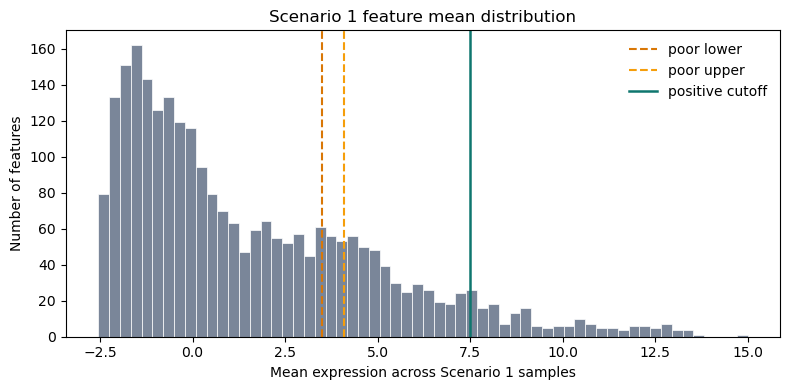

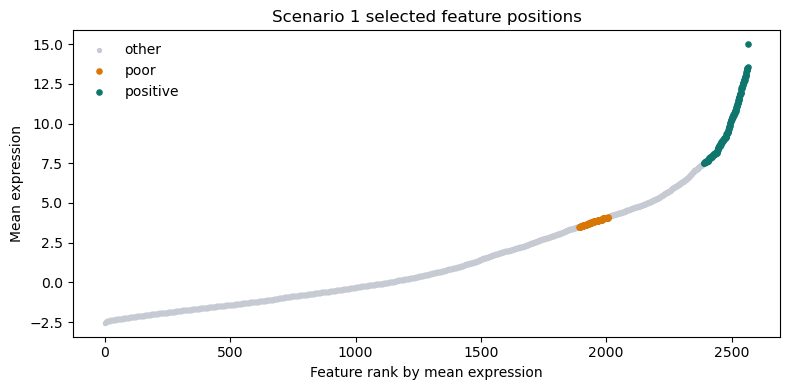

Threshold visualization passed.


In [11]:
plot_feature_mean_thresholds(
    s1_feature_means,
    S1_POOR_LOWER,
    S1_POOR_UPPER,
    S1_POSITIVE_CUTOFF,
    title="Scenario 1 feature mean distribution",
    sample_label="Scenario 1 samples",
)
plt.show()

plot_selected_feature_means(s1_feature_means, s1_poor_mask, s1_positive_mask)
plt.show()

print("Threshold visualization passed.")


### Frozen batch labels

Scenario 1 uses validated frozen inferred batch labels. The Pro notebook does not rerun UMAP/KMeans batch inference.


In [12]:
from pathlib import Path

print("Current working directory:")
print(Path.cwd())

print("\nFrozen batch directory:")
print((Path.cwd() / "frozen_batches").resolve())

print("\nExisting frozen files:")
frozen_dir = Path("frozen_batches")
if frozen_dir.exists():
    for p in sorted(frozen_dir.glob("*")):
        print(" -", p.name)
else:
    print("frozen_batches/ does not exist")

Current working directory:
C:\Users\apple\Desktop\RNASeq_with_Python\1Yokoi

Frozen batch directory:
C:\Users\apple\Desktop\RNASeq_with_Python\1Yokoi\frozen_batches

Existing frozen files:
 - README.md
 - s1_inferred_batches.csv
 - s2_inferred_batches.csv
 - s3_inferred_batches.csv


In [13]:
s1_batch_labels = load_frozen_batches("s1", s1_expression.columns)
assert s1_batch_labels.index.equals(s1_expression.columns)
display(s1_batch_labels.value_counts().sort_index())


batch
batch_1    1672
batch_2    1407
Name: count, dtype: int64

### Fixed MIMAT signature

The R workflow evaluates both the broader `s1_positive_data` feature set and a fixed Scenario 1 MIMAT signature. These feature sets remain separate so they can be run as distinct experiment variants.

The R workflow subsets the fixed signature with `%in%`, so only MIMAT IDs present in the Yokoi expression matrix are used. The Python reproduction tracks missing requested IDs without changing the %in% subset behavior.


In [14]:
yokoi_model1_mimat = [
    "MIMAT0000510",  # miR-320a
    "MIMAT0000762",  # miR-665
    "MIMAT0015090",  # miR-3184-5p
    "MIMAT0022706",  # miR-6717-5p
    "MIMAT0019654",  # miR-4459
    "MIMAT0022715",  # miR-6076
    "MIMAT0015081",  # miR-3195
    "MIMAT0015056",  # miR-1275
    "MIMAT0015087",  # miR-3185
    "MIMAT0019683",  # miR-4640-5p
]

s1_expression_feature_ids = s1_expression.index.astype(str)
s1_model1_found_mimat = [mimat for mimat in yokoi_model1_mimat if mimat in s1_expression.index]
s1_model1_missing_mimat = [mimat for mimat in yokoi_model1_mimat if mimat not in s1_expression.index]
s1_model1_missing_id_candidates = {
    mimat: [
        feature_id
        for feature_id in s1_expression_feature_ids
        if feature_id == mimat or feature_id.strip() == mimat or feature_id.startswith(f"{mimat}.")
    ]
    for mimat in s1_model1_missing_mimat
}

s1_model1_membership = pd.Series(
    {
        "requested signature features": len(yokoi_model1_mimat),
        "found features": len(s1_model1_found_mimat),
        "missing features": len(s1_model1_missing_mimat),
    },
    name="count",
)
if not s1_model1_found_mimat:
    raise ValueError("no fixed Scenario 1 MIMAT IDs are present in s1_expression")

s1_model1_expression = s1_expression.loc[s1_model1_found_mimat].copy()

assert len(yokoi_model1_mimat) == 10
assert len(s1_model1_found_mimat) > 0
assert s1_model1_expression.shape[0] == len(s1_model1_found_mimat)
assert list(s1_model1_expression.index) == s1_model1_found_mimat
assert s1_model1_expression.columns.equals(s1_expression.columns)


### SSV runtime and Scenario 1 datasets

The generic Python SSV runtime is loaded from `SSV_Python_Reproduction_pro.ipynb`. Scenario-specific matrices are wrapped as `MolecularDataset` objects after alignment validation.


In [15]:
s1_batch_mode = "temporal" if BATCH_TIME else "random"
s1_expression_source = "raw_counts" if DATA_TYPE_RNASEQ else "transformed_expression"

s1_positive_dataset = MolecularDataset(
    expression=s1_positive_data,
    class_labels=s1_labels,
    batch_labels=s1_batch_labels,
)
s1_model1_dataset = MolecularDataset(
    expression=s1_model1_expression,
    class_labels=s1_labels,
    batch_labels=s1_batch_labels,
)

validate_molecular_dataset(s1_positive_dataset)
validate_molecular_dataset(s1_model1_dataset)


MolecularDataset(expression=sample_id     GSM2851338  GSM2851339  GSM2851340  GSM2851341  GSM2851342  \
feature_id                                                                 
MIMAT0000510       6.251       4.609       5.056       4.698       4.537   
MIMAT0000762       3.331       2.823       2.137      -1.089      -0.915   
MIMAT0015090       0.516      -2.605      -1.809      -1.089      -0.915   
MIMAT0022706       0.516      -2.605      -1.809      -1.089      -0.915   
MIMAT0015081       0.516      -2.605      -1.809      -1.089      -0.915   
MIMAT0015056       0.516      -2.605      -1.809      -1.089      -0.915   
MIMAT0015087       0.516       2.455      -1.809      -1.089      -0.915   

sample_id     GSM2851343  GSM2851344  GSM2851345  GSM2851346  GSM2851347  ...  \
feature_id                                                                ...   
MIMAT0000510       3.402       4.012       5.143       2.300       4.258  ...   
MIMAT0000762      -1.174       2.604       2

## Scenario 2 - Ovarian cancer vs other cancers

Scenario 2 compares ovarian cancer with the other cancer classes listed in the R workflow. The raw disease labels are kept for reference checks, while binary labels are used for later modeling.


### Scenario definition


In [16]:
S2_POSITIVE_CLASS = "Ovarian Cancer"
S2_NEGATIVE_CLASSES = (
    "Breast Cancer",
    "Colorectal Cancer",
    "Esophageal Cancer",
    "Gastric Cancer",
    "Hepatocellular Carcinoma",
    "Lung Cancer",
    "Pancreatic Cancer",
    "Sarcoma",
)
S2_INCLUDED_CLASSES = (S2_POSITIVE_CLASS, *S2_NEGATIVE_CLASSES)

S2_POOR_LOWER = 3.1
S2_POOR_UPPER = 3.7
S2_POSITIVE_CUTOFF = 7.5


### Poor and positive feature selection


In [17]:
s2_mask = class_labels_raw.isin(S2_INCLUDED_CLASSES)
s2_sample_ids = class_labels_raw.index[s2_mask]

s2_expression = expression_all.loc[:, s2_sample_ids].copy()
s2_class_raw = class_labels_raw.loc[s2_sample_ids].copy()
s2_labels = s2_class_raw.eq(S2_POSITIVE_CLASS).astype(int)
s2_labels.name = "class"
s2_binary_class = s2_labels.map({1: "Ovarian Cancer", 0: "Other cancers"})
s2_binary_class.name = "binary_class"

assert s2_expression.columns.equals(s2_labels.index)
assert s2_expression.columns.equals(s2_class_raw.index)
assert set(s2_labels.unique()) == {0, 1}
assert "non-Cancer" not in set(s2_class_raw.unique())

s2_class_counts = s2_class_raw.value_counts().reindex(S2_INCLUDED_CLASSES)
s2_expected_total = int(class_labels_raw.value_counts().reindex(S2_INCLUDED_CLASSES).sum())
assert s2_expression.shape[1] == s2_expected_total

s2_feature_means = s2_expression.mean(axis=1)
assert s2_feature_means.index.equals(s2_expression.index)
assert s2_feature_means.map(math.isfinite).all()

s2_thresholds = (S2_POOR_LOWER, S2_POOR_UPPER, S2_POSITIVE_CUTOFF)
assert all(math.isfinite(value) for value in s2_thresholds)
assert S2_POOR_LOWER < S2_POOR_UPPER

s2_poor_mask = (s2_feature_means > S2_POOR_LOWER) & (s2_feature_means < S2_POOR_UPPER)
s2_positive_mask = s2_feature_means > S2_POSITIVE_CUTOFF

s2_poor_data = s2_expression.loc[s2_poor_mask].copy()
s2_positive_data = s2_expression.loc[s2_positive_mask].copy()

if s2_poor_data.empty:
    raise ValueError("s2_poor_data has no selected features; adjust S2_POOR_LOWER or S2_POOR_UPPER")
if s2_positive_data.empty:
    raise ValueError("s2_positive_data has no selected features; adjust S2_POSITIVE_CUTOFF")

assert ((s2_feature_means.loc[s2_poor_data.index] > S2_POOR_LOWER) & (s2_feature_means.loc[s2_poor_data.index] < S2_POOR_UPPER)).all()
assert (s2_feature_means.loc[s2_positive_data.index] > S2_POSITIVE_CUTOFF).all()
assert s2_poor_data.columns.equals(s2_expression.columns)
assert s2_positive_data.columns.equals(s2_expression.columns)

s2_selection_summary = pd.Series(
    {
        "Scenario 2 samples": s2_expression.shape[1],
        "Ovarian Cancer samples": int(s2_labels.sum()),
        "Other-cancer samples": int((s2_labels == 0).sum()),
        "total features": s2_expression.shape[0],
        "poor features": s2_poor_data.shape[0],
        "positive features": s2_positive_data.shape[0],
    },
    name="count",
)

print("Scenario 2 prepared.")
display(s2_selection_summary.to_frame())
display(s2_class_counts.rename("n_samples").to_frame())


Scenario 2 prepared.


,count
Scenario 2 samples,1179
Ovarian Cancer samples,320
Other-cancer samples,859
total features,2565
poor features,142
positive features,204


,n_samples
class_label_raw,
Ovarian Cancer,320
Breast Cancer,115
Colorectal Cancer,115
Esophageal Cancer,88
Gastric Cancer,115
Hepatocellular Carcinoma,81
Lung Cancer,115
Pancreatic Cancer,115
Sarcoma,115


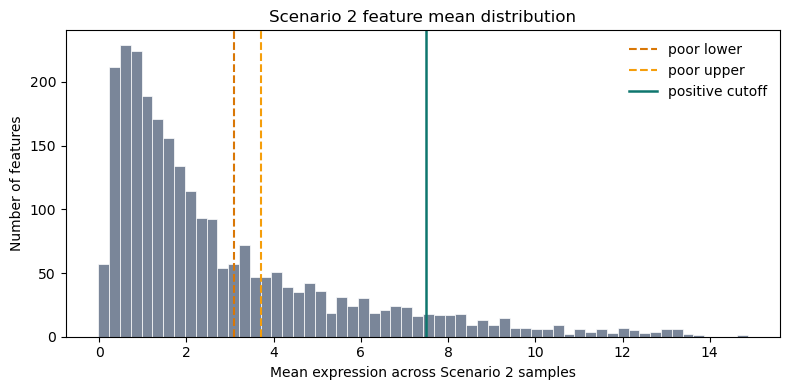

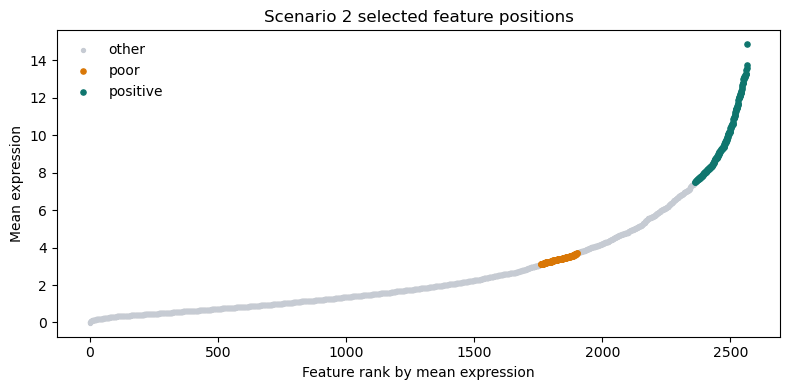

In [18]:
plot_feature_mean_thresholds(
    s2_feature_means,
    S2_POOR_LOWER,
    S2_POOR_UPPER,
    S2_POSITIVE_CUTOFF,
    title="Scenario 2 feature mean distribution",
    sample_label="Scenario 2 samples",
)
plt.show()

plot_selected_feature_means(
    s2_feature_means,
    s2_poor_mask,
    s2_positive_mask,
    title="Scenario 2 selected feature positions",
)
plt.show()


### Frozen batch labels


In [19]:
s2_batch_labels = load_frozen_batches("s2", s2_expression.columns)
assert s2_batch_labels.index.equals(s2_expression.columns)
display(s2_batch_labels.value_counts().sort_index())


batch
batch_1    797
batch_2    382
Name: count, dtype: int64

In [20]:
yokoi_model2_mimat = [
    "MIMAT0019695",  # miR-4687-3p
    "MIMAT0004982",  # miR-939-5p
    "MIMAT0022765",  # miR-5739
    "MIMAT0000288",  # miR-211-3p
    "MIMAT0015078",  # miR-1273g-3p
    "MIMAT0018075",  # miR-3663-3p
    "MIMAT0019904",  # miR-4726-5p
    "MIMAT0019923",  # miR-4745-5p
    "MIMAT0016894",  # miR-1268b
    "MIMAT0003322",  # miR-658
]

s2_expression_feature_ids = s2_expression.index.astype(str)
s2_model2_found_mimat = [mimat for mimat in yokoi_model2_mimat if mimat in s2_expression.index]
s2_model2_missing_mimat = [mimat for mimat in yokoi_model2_mimat if mimat not in s2_expression.index]
s2_model2_missing_id_candidates = {
    mimat: [
        feature_id
        for feature_id in s2_expression_feature_ids
        if feature_id == mimat or feature_id.strip() == mimat or feature_id.startswith(f"{mimat}.")
    ]
    for mimat in s2_model2_missing_mimat
}

s2_model2_membership = pd.Series(
    {
        "requested signature features": len(yokoi_model2_mimat),
        "found features": len(s2_model2_found_mimat),
        "missing features": len(s2_model2_missing_mimat),
    },
    name="count",
)
if not s2_model2_found_mimat:
    raise ValueError("no fixed Scenario 2 MIMAT IDs are present in s2_expression")

s2_model2_expression = s2_expression.loc[s2_model2_found_mimat].copy()

assert len(yokoi_model2_mimat) == 10
assert len(s2_model2_found_mimat) > 0
assert s2_model2_expression.shape[0] == len(s2_model2_found_mimat)
assert list(s2_model2_expression.index) == s2_model2_found_mimat
assert s2_model2_expression.columns.equals(s2_expression.columns)


### Scenario 2 datasets

The broad Scenario 2 feature set and fixed MIMAT signature are wrapped as `MolecularDataset` objects for the generic SSV runtime.


In [21]:
s2_batch_mode = "temporal" if BATCH_TIME else "random"
s2_expression_source = "raw_counts" if DATA_TYPE_RNASEQ else "transformed_expression"

s2_positive_dataset = MolecularDataset(
    expression=s2_positive_data,
    class_labels=s2_labels,
    batch_labels=s2_batch_labels,
)
s2_model2_dataset = MolecularDataset(
    expression=s2_model2_expression,
    class_labels=s2_labels,
    batch_labels=s2_batch_labels,
)

validate_molecular_dataset(s2_positive_dataset)
validate_molecular_dataset(s2_model2_dataset)


MolecularDataset(expression=sample_id     GSM2850709  GSM2850710  GSM2850711  GSM2850712  GSM2850713  \
feature_id                                                                 
MIMAT0019695       5.288       1.941       4.053       0.415      -0.586   
MIMAT0004982       5.665       6.696       6.085       3.107       6.439   
MIMAT0015078       0.333       1.941       0.371       5.643      -0.586   
MIMAT0018075       3.662       1.941       0.371       0.415      -0.586   
MIMAT0019904       5.860       3.662       4.042       0.415       6.001   
MIMAT0019923       5.444       7.314       4.707       8.554       5.544   
MIMAT0016894       0.333       1.941       0.371       0.415      -0.586   
MIMAT0003322       4.627       1.941       1.909       5.873       5.475   

sample_id     GSM2850714  GSM2850715  GSM2850716  GSM2850717  GSM2850718  ...  \
feature_id                                                                ...   
MIMAT0019695       3.183       2.897       4.284 

## Scenario 3 - Ovarian cancer vs benign / borderline / non-cancer controls

Scenario 3 compares ovarian cancer with benign ovarian disease, borderline ovarian tumor, and non-cancer controls. The raw disease labels are kept for reference checks, while binary labels are used only to visualize outcome balance across inferred batches.

### Scenario definition

In [22]:
S3_POSITIVE_CLASS = "Ovarian Cancer"

S3_NEGATIVE_CLASSES = (
    "Benign Ovarian Disease",
    "Borderline Ovarian Tumor",
    "non-Cancer",
)

S3_INCLUDED_CLASSES = (S3_POSITIVE_CLASS, *S3_NEGATIVE_CLASSES)

S3_POOR_LOWER = 3.5
S3_POOR_UPPER = 4.1
S3_POSITIVE_CUTOFF = 7.5

### Poor and positive feature selection

In [23]:
s3_mask = class_labels_raw.isin(S3_INCLUDED_CLASSES)
s3_sample_ids = class_labels_raw.index[s3_mask]

s3_expression = expression_all.loc[:, s3_sample_ids].copy()
s3_class_raw = class_labels_raw.loc[s3_sample_ids].copy()
s3_labels = s3_class_raw.eq(S3_POSITIVE_CLASS).astype(int)
s3_labels.name = "class"
s3_binary_class = s3_labels.map({1: "Ovarian Cancer", 0: "Benign/borderline/non-cancer"})
s3_binary_class.name = "binary_class"

assert s3_expression.columns.equals(s3_labels.index)
assert s3_expression.columns.equals(s3_class_raw.index)
assert set(s3_labels.unique()) == {0, 1}
assert set(s3_class_raw.unique()) == set(S3_INCLUDED_CLASSES)

s3_class_counts = s3_class_raw.value_counts().reindex(S3_INCLUDED_CLASSES)
s3_expected_total = int(class_labels_raw.value_counts().reindex(S3_INCLUDED_CLASSES).sum())
assert s3_expression.shape[1] == s3_expected_total

s3_feature_means = s3_expression.mean(axis=1)
assert s3_feature_means.index.equals(s3_expression.index)
assert s3_feature_means.map(math.isfinite).all()

s3_thresholds = (S3_POOR_LOWER, S3_POOR_UPPER, S3_POSITIVE_CUTOFF)
assert all(math.isfinite(value) for value in s3_thresholds)
assert S3_POOR_LOWER < S3_POOR_UPPER

s3_poor_mask = (s3_feature_means > S3_POOR_LOWER) & (s3_feature_means < S3_POOR_UPPER)
s3_positive_mask = s3_feature_means > S3_POSITIVE_CUTOFF

s3_poor_data = s3_expression.loc[s3_poor_mask].copy()
s3_positive_data = s3_expression.loc[s3_positive_mask].copy()

if s3_poor_data.empty:
    raise ValueError("s3_poor_data has no selected features; adjust S3_POOR_LOWER or S3_POOR_UPPER")
if s3_positive_data.empty:
    raise ValueError("s3_positive_data has no selected features; adjust S3_POSITIVE_CUTOFF")

assert ((s3_feature_means.loc[s3_poor_data.index] > S3_POOR_LOWER) & (s3_feature_means.loc[s3_poor_data.index] < S3_POOR_UPPER)).all()
assert (s3_feature_means.loc[s3_positive_data.index] > S3_POSITIVE_CUTOFF).all()
assert s3_poor_data.columns.equals(s3_expression.columns)
assert s3_positive_data.columns.equals(s3_expression.columns)

s3_selection_summary = pd.Series(
    {
        "Scenario 3 samples": s3_expression.shape[1],
        "Ovarian Cancer samples": int(s3_labels.sum()),
        "control samples": int((s3_labels == 0).sum()),
        "total features": s3_expression.shape[0],
        "poor features": s3_poor_data.shape[0],
        "positive features": s3_positive_data.shape[0],
    },
    name="count",
)

print("Scenario 3 prepared.")
display(s3_selection_summary.to_frame())
display(s3_class_counts.rename("n_samples").to_frame())

Scenario 3 prepared.


,count
Scenario 3 samples,3174
Ovarian Cancer samples,320
control samples,2854
total features,2565
poor features,117
positive features,176


,n_samples
class_label_raw,
Ovarian Cancer,320
Benign Ovarian Disease,29
Borderline Ovarian Tumor,66
non-Cancer,2759


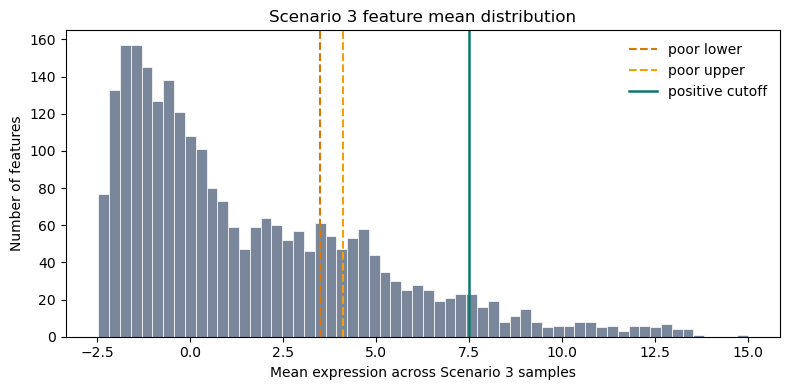

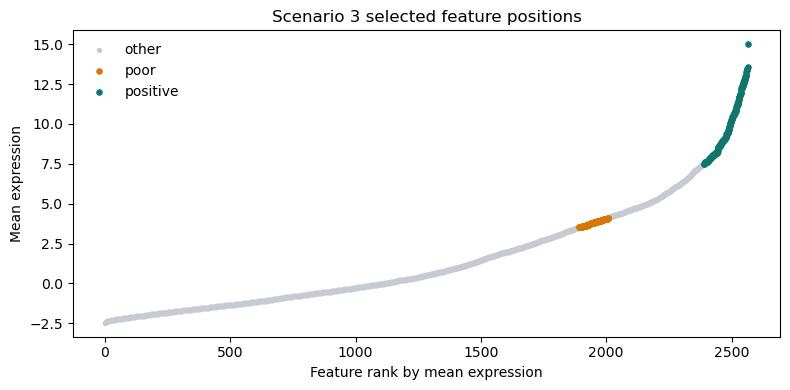

In [24]:
plot_feature_mean_thresholds(
    s3_feature_means,
    S3_POOR_LOWER,
    S3_POOR_UPPER,
    S3_POSITIVE_CUTOFF,
    title="Scenario 3 feature mean distribution",
    sample_label="Scenario 3 samples",
)
plt.show()

plot_selected_feature_means(
    s3_feature_means,
    s3_poor_mask,
    s3_positive_mask,
    title="Scenario 3 selected feature positions",
)
plt.show()

### Frozen batch labels


In [25]:
s3_batch_labels = load_frozen_batches("s3", s3_expression.columns)
assert s3_batch_labels.index.equals(s3_expression.columns)
display(s3_batch_labels.value_counts().sort_index())


batch
batch_1    1443
batch_2    1731
Name: count, dtype: int64

In [26]:
yokoi_model3_mimat = [
    "MIMAT0003325",  # miR-663b
    "MIMAT0019915",  # miR-4730
    "MIMAT0003301",  # miR-642a-3p
    "MIMAT0003322",  # miR-658
    "MIMAT0002177",  # miR-486-3p
    "MIMAT0005898",  # miR-1246
    "MIMAT0005858",  # miR-1207-5p
    "MIMAT0019961",  # miR-4419b
    "MIMAT0023723",  # miR-6124
]

s3_expression_feature_ids = s3_expression.index.astype(str)
s3_model3_found_mimat = [mimat for mimat in yokoi_model3_mimat if mimat in s3_expression.index]
s3_model3_missing_mimat = [mimat for mimat in yokoi_model3_mimat if mimat not in s3_expression.index]
s3_model3_missing_id_candidates = {
    mimat: [
        feature_id
        for feature_id in s3_expression_feature_ids
        if feature_id == mimat
        or feature_id.strip() == mimat
        or any(feature_id == f"{mimat}.{suffix}" for suffix in range(1, 10))
    ]
    for mimat in s3_model3_missing_mimat
}

s3_model3_membership = pd.Series(
    {
        "requested signature features": len(yokoi_model3_mimat),
        "found features": len(s3_model3_found_mimat),
        "missing features": len(s3_model3_missing_mimat),
    },
    name="count",
)
if not s3_model3_found_mimat:
    raise ValueError("no fixed Scenario 3 MIMAT IDs are present in s3_expression")

s3_model3_expression = s3_expression.loc[s3_model3_found_mimat].copy()

assert len(yokoi_model3_mimat) == 9
assert len(s3_model3_found_mimat) > 0
assert s3_model3_expression.shape[0] == len(s3_model3_found_mimat)
assert list(s3_model3_expression.index) == s3_model3_found_mimat
assert s3_model3_expression.columns.equals(s3_expression.columns)

### Scenario 3 datasets

The broad Scenario 3 feature set and fixed MIMAT signature are wrapped as `MolecularDataset` objects for the generic SSV runtime.


In [27]:
s3_batch_mode = "temporal" if BATCH_TIME else "random"
s3_expression_source = "raw_counts" if DATA_TYPE_RNASEQ else "transformed_expression"

s3_positive_dataset = MolecularDataset(
    expression=s3_positive_data,
    class_labels=s3_labels,
    batch_labels=s3_batch_labels,
)
s3_model3_dataset = MolecularDataset(
    expression=s3_model3_expression,
    class_labels=s3_labels,
    batch_labels=s3_batch_labels,
)

validate_molecular_dataset(s3_positive_dataset)
validate_molecular_dataset(s3_model3_dataset)


MolecularDataset(expression=sample_id     GSM2851338  GSM2851339  GSM2851340  GSM2851341  GSM2851342  \
feature_id                                                                 
MIMAT0003325       2.925      -2.605       2.946       2.579      -0.915   
MIMAT0019915       0.516       2.115       2.340      -1.089      -0.915   
MIMAT0003301       0.516      -2.605       3.714       1.305      -0.915   
MIMAT0003322       5.649      -2.605      -1.809      -1.089       4.927   
MIMAT0002177       7.727       5.775       7.247       6.044       6.676   
MIMAT0005898       0.516       0.333       3.591      -1.089       5.845   
MIMAT0019961       3.824       2.152       1.849       2.703      -0.915   

sample_id     GSM2851343  GSM2851344  GSM2851345  GSM2851346  GSM2851347  ...  \
feature_id                                                                ...   
MIMAT0003325      -1.174      -2.321       1.169      -1.215      -0.207  ...   
MIMAT0019915      -1.174      -2.321       1

## Batch-Structure QC and Poor-Marker Boxplots

These compact diagnostics use the generic Pro helpers. They do not change the downstream Pro modeling protocol.


### Scenario 1

,domain,metric,ratio,minority_proportion,cramers_v,abs_prevalence_difference,chi_square_p_value,status
0,label_balance,max_class_count / min_class_count,8.621875,0.103930,NaN,NaN,NaN,HIGH
1,batch_balance,max_batch_count / min_batch_count,1.188344,0.456967,NaN,NaN,NaN,LOW
2,label_batch_association,Cramer's V and max class-prevalence range acro...,NaN,NaN,0.046512,0.028494,0.009854,LOW


class,Ovarian Cancer,non-Cancer
batch,,
batch_1,152,1520
batch_2,168,1239


,retained_samples_for_plot,batch_class_strata
0,320,4


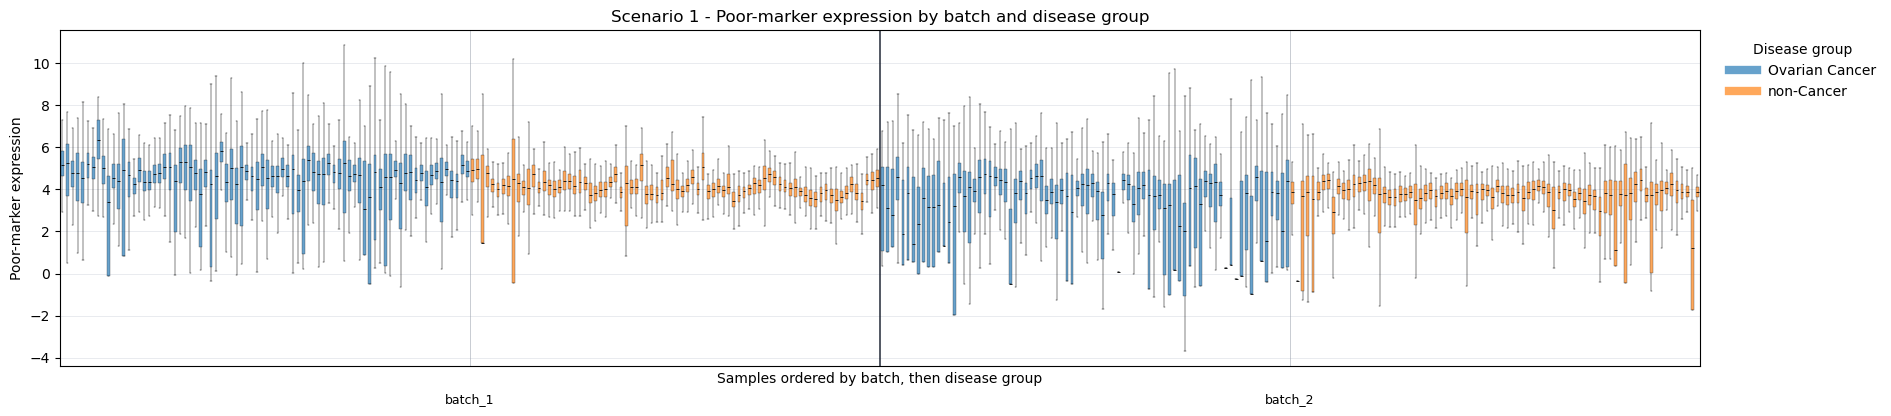

### Scenario 2

,domain,metric,ratio,minority_proportion,cramers_v,abs_prevalence_difference,chi_square_p_value,status
0,label_balance,max_class_count / min_class_count,2.684375,0.271416,NaN,NaN,NaN,MODERATE
1,batch_balance,max_batch_count / min_batch_count,2.086387,0.324003,NaN,NaN,NaN,MODERATE
2,label_batch_association,Cramer's V and max class-prevalence range acro...,NaN,NaN,0.025753,0.02447,0.376555,LOW


class,Other cancers,Ovarian Cancer
batch,,
batch_1,587,210
batch_2,272,110


,retained_samples_for_plot,batch_class_strata
0,956,18


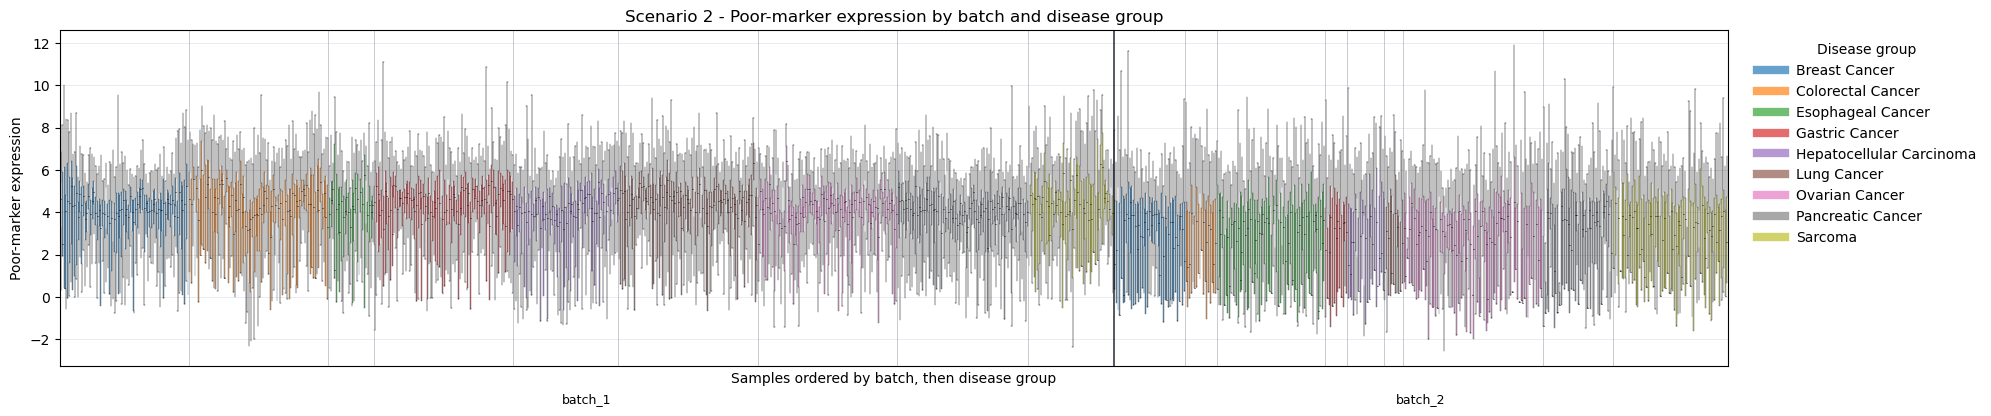

### Scenario 3

,domain,metric,ratio,minority_proportion,cramers_v,abs_prevalence_difference,chi_square_p_value,status
0,label_balance,max_class_count / min_class_count,8.918750,0.100819,NaN,NaN,NaN,HIGH
1,batch_balance,max_batch_count / min_batch_count,1.199584,0.454631,NaN,NaN,NaN,LOW
2,label_batch_association,Cramer's V and max class-prevalence range acro...,NaN,NaN,0.173409,0.104856,1.521051e-22,MODERATE


class,Benign/borderline/non-cancer,Ovarian Cancer
batch,,
batch_1,1215,228
batch_2,1639,92


,retained_samples_for_plot,batch_class_strata
0,415,8


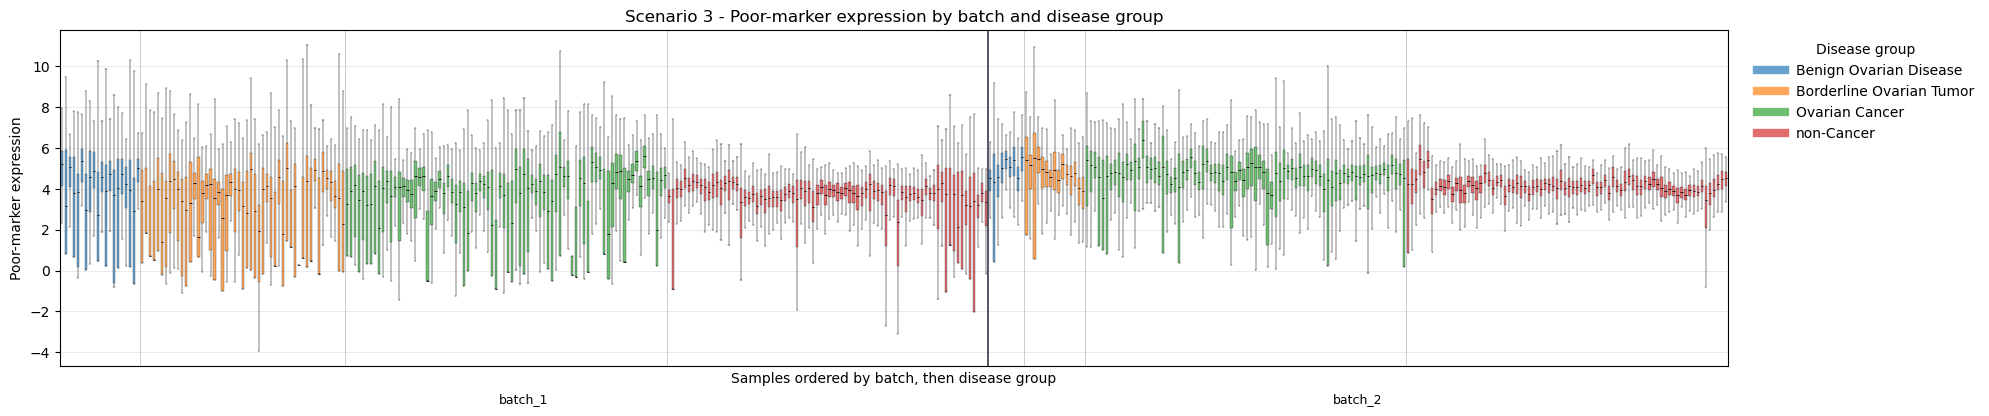

In [28]:
try:
    from IPython.display import Markdown
except ImportError:
    Markdown = None

YOKOI_QC_BOXPLOT_MAX_SAMPLES_PER_STRATUM = 80

YOKOI_SCENARIO_DIAGNOSTICS = {
    "Scenario 1": {
        "qc_dataset": MolecularDataset(
            expression=s1_poor_data,
            class_labels=s1_labels.map({0: "non-Cancer", 1: "Ovarian Cancer"}).rename("class"),
            batch_labels=s1_batch_labels,
        ),
        "poor_expression": s1_poor_data,
        "boxplot_class_labels": s1_class_raw.rename("class"),
        "batch_labels": s1_batch_labels,
        "title": "Scenario 1 - Poor-marker expression by batch and disease group",
    },
    "Scenario 2": {
        "qc_dataset": MolecularDataset(
            expression=s2_poor_data,
            class_labels=s2_binary_class.rename("class"),
            batch_labels=s2_batch_labels,
        ),
        "poor_expression": s2_poor_data,
        "boxplot_class_labels": s2_class_raw.rename("class"),
        "batch_labels": s2_batch_labels,
        "title": "Scenario 2 - Poor-marker expression by batch and disease group",
    },
    "Scenario 3": {
        "qc_dataset": MolecularDataset(
            expression=s3_poor_data,
            class_labels=s3_binary_class.rename("class"),
            batch_labels=s3_batch_labels,
        ),
        "poor_expression": s3_poor_data,
        "boxplot_class_labels": s3_class_raw.rename("class"),
        "batch_labels": s3_batch_labels,
        "title": "Scenario 3 - Poor-marker expression by batch and disease group",
    },
}

for scenario_name, entry in YOKOI_SCENARIO_DIAGNOSTICS.items():
    if Markdown is not None:
        display(Markdown(f"### {scenario_name}"))
    else:
        print(f"### {scenario_name}")

    qc_summary, batch_class_table = summarize_batch_structure(
        entry["qc_dataset"],
        scenario=scenario_name,
    )
    display(
        qc_summary[
            [
                "domain",
                "metric",
                "ratio",
                "minority_proportion",
                "cramers_v",
                "abs_prevalence_difference",
                "chi_square_p_value",
                "status",
            ]
        ]
    )
    display(batch_class_table)
    assert int(batch_class_table.to_numpy().sum()) == entry["qc_dataset"].expression.shape[1]
    if entry["qc_dataset"].class_labels.nunique() == 2 and entry["qc_dataset"].batch_labels.nunique() == 2:
        assert batch_class_table.shape == (2, 2)

    fig, ax, ordered_samples = plot_poor_marker_samplewise_boxplot(
        entry["poor_expression"],
        entry["boxplot_class_labels"],
        entry["batch_labels"],
        title=entry["title"],
        max_samples_per_stratum=YOKOI_QC_BOXPLOT_MAX_SAMPLES_PER_STRATUM,
        seed=YOKOI_STRUCTURE_SEED,
    )
    assert ordered_samples.shape[0] == len(ax.artists) or ordered_samples.shape[0] > 0
    display(
        pd.DataFrame(
            [
                {
                    "retained_samples_for_plot": int(ordered_samples.shape[0]),
                    "batch_class_strata": int(ordered_samples.groupby(["batch", "class"]).ngroups),
                }
            ]
        )
    )
    plt.show()


### QC interpretation note

Composition diagnostics and expression-level evidence are evaluated separately. Label imbalance is assessed from the model label; after frozen inferred batch labels exist, batch imbalance and label-batch association are evaluated before batch-aware validation. The sample-wise poor-marker boxplot compares within-batch disease-group differences with between-batch expression shifts and does not alter the Pro modeling protocol.


## Yokoi R-style SSV run

The formal Yokoi reproduction uses the original R workflow semantics: `batch_time=False` and `batch_balance=True`. Raw batch labels are randomly grouped once per repetition, and balancing is repeated independently inside each split percentage.

### Experiment registry

In [29]:
YOKOI_PRO_EXPERIMENTS = {
    "s1_positive": {
        "dataset": s1_positive_dataset,
        "scenario": "s1",
        "feature_set": "positive",
        "output_name": "yokoi_s1_positive",
    },
    #"s1_model1": {
        #"dataset": s1_model1_dataset,
        #"scenario": "s1",
        #"feature_set": "model1",
        #"output_name": "yokoi_s1_model1",
    #},
    "s2_positive": {
        "dataset": s2_positive_dataset,
        "scenario": "s2",
        "feature_set": "positive",
        "output_name": "yokoi_s2_positive",
    },
    #"s2_model2": {
        #"dataset": s2_model2_dataset,
        #"scenario": "s2",
        #"feature_set": "model2",
        #"output_name": "yokoi_s2_model2",
    #},
    "s3_positive": {
        "dataset": s3_positive_dataset,
        "scenario": "s3",
        "feature_set": "positive",
        "output_name": "yokoi_s3_positive",
    },
    #"s3_model3": {
        #"dataset": s3_model3_dataset,
        #"scenario": "s3",
        #"feature_set": "model3",
        #"output_name": "yokoi_s3_model3",
    #},
}

YOKOI_PRO_RUN_ORDER = (
    "s1_positive",
    #"s1_model1",
    "s2_positive",
    #"s2_model2",
    "s3_positive",
    #"s3_model3",
)

missing_yokoi_experiments = [name for name in YOKOI_PRO_RUN_ORDER if name not in YOKOI_PRO_EXPERIMENTS]
if missing_yokoi_experiments:
    raise ValueError(f"YOKOI_PRO_RUN_ORDER contains unknown experiments: {missing_yokoi_experiments}")

assert set(YOKOI_PRO_RUN_ORDER) == set(YOKOI_PRO_EXPERIMENTS)
assert all(isinstance(entry["dataset"], MolecularDataset) for entry in YOKOI_PRO_EXPERIMENTS.values())


### Run Yokoi experiments


s1_positive | natural
s1_positive | class_stratified
s2_positive | natural
s2_positive | class_stratified
s3_positive | natural
s3_positive | class_stratified


,experiment,output_name,prevalence_mode,status,n_raw_rows,output_directory
0,s1_positive,yokoi_s1_positive,natural,complete,2000,results_pro\yokoi_s1_positive\natural
1,s1_positive,yokoi_s1_positive,class_stratified,complete,2000,results_pro\yokoi_s1_positive\class_stratified
2,s2_positive,yokoi_s2_positive,natural,complete,2000,results_pro\yokoi_s2_positive\natural
3,s2_positive,yokoi_s2_positive,class_stratified,complete,2000,results_pro\yokoi_s2_positive\class_stratified
4,s3_positive,yokoi_s3_positive,natural,complete,2000,results_pro\yokoi_s3_positive\natural
5,s3_positive,yokoi_s3_positive,class_stratified,complete,2000,results_pro\yokoi_s3_positive\class_stratified


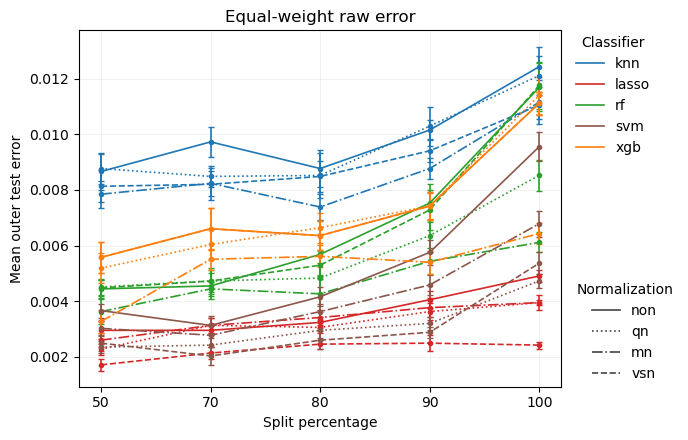

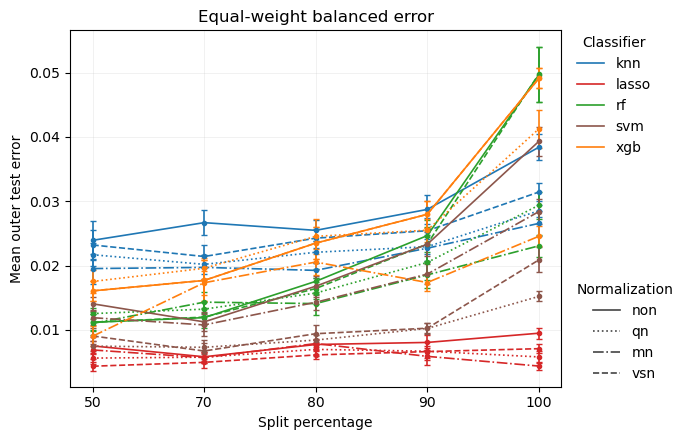

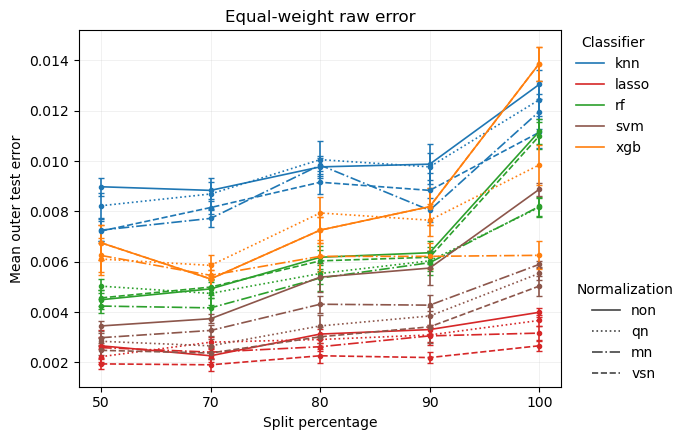

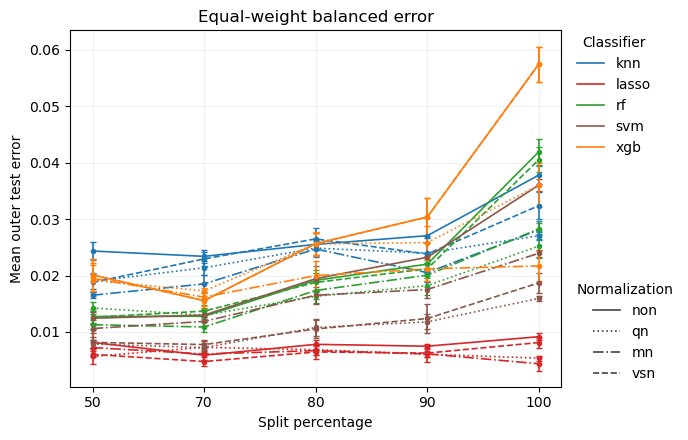

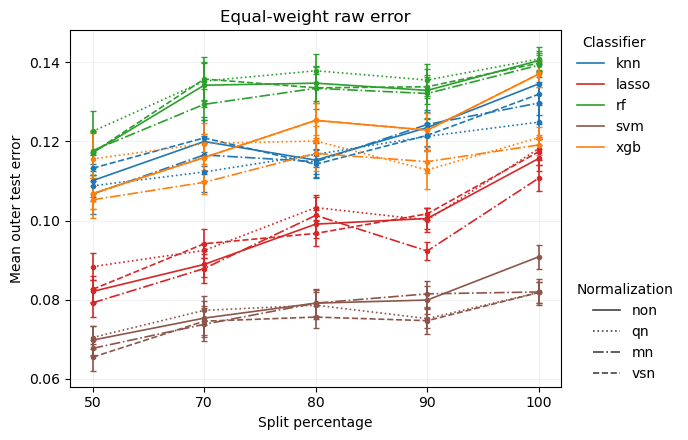

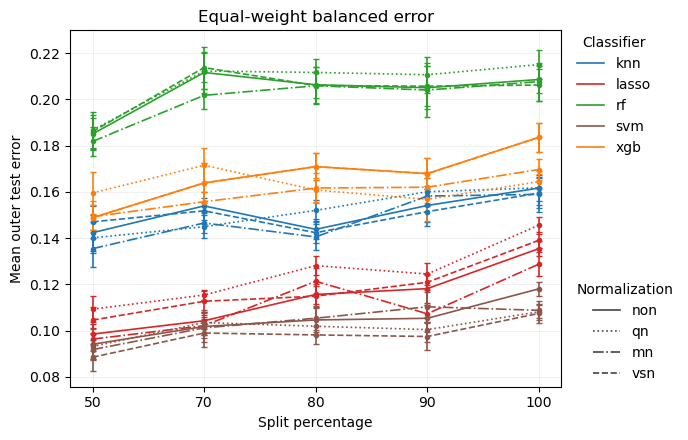

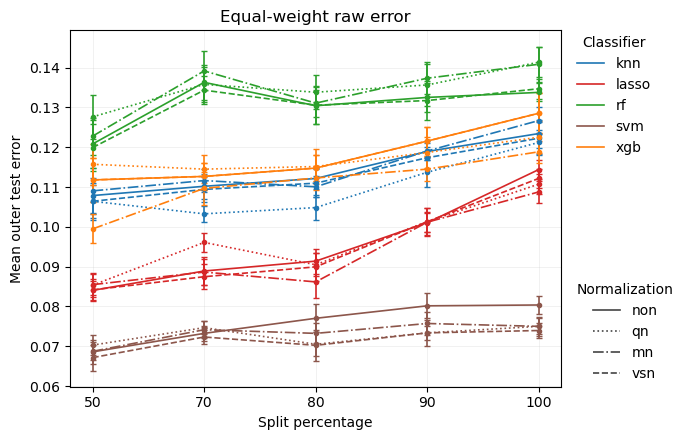

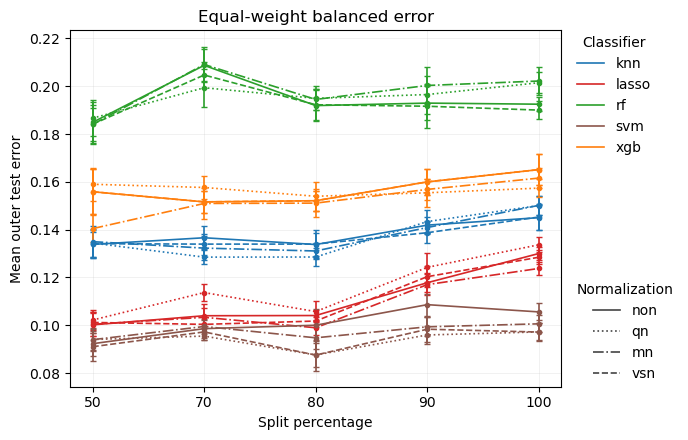

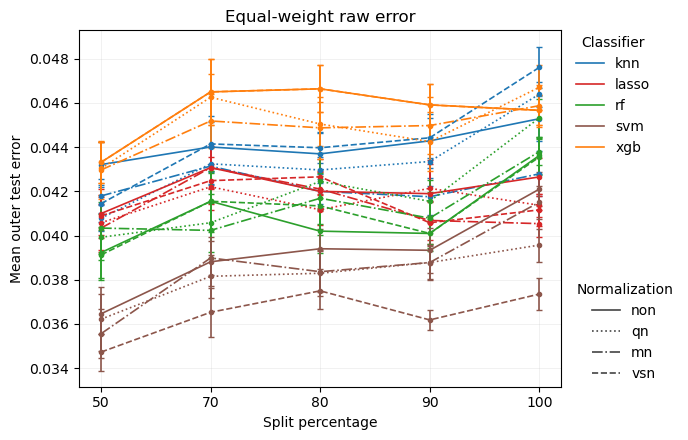

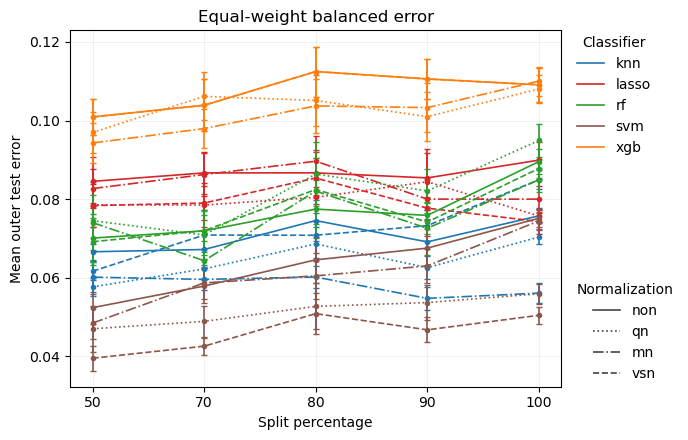

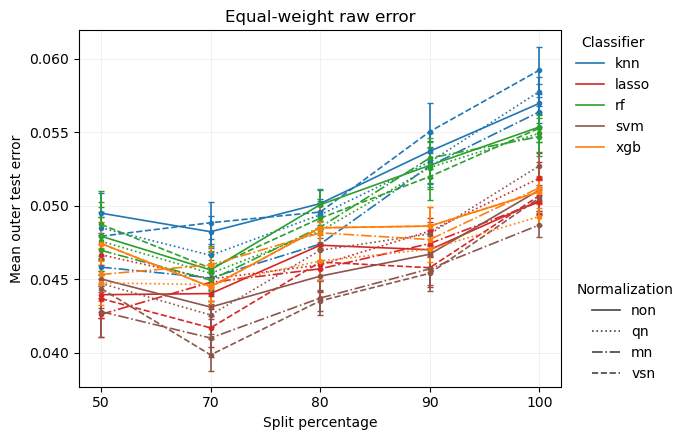

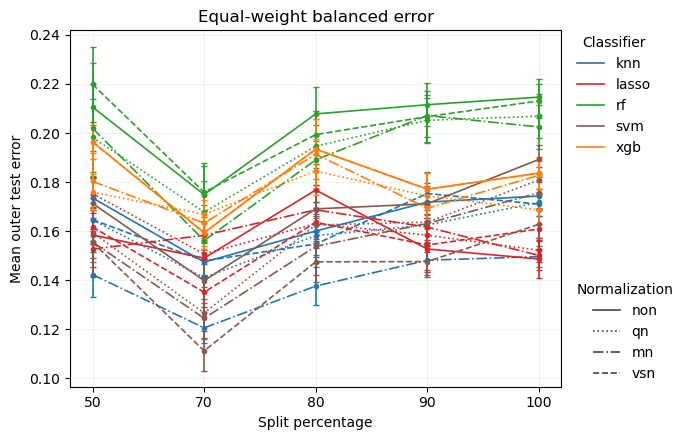

In [40]:
PRO_TEST_MODE = False
RUN_FULL_PRO = True

PRO_TIMES = 10
PRO_SPLITS = (50, 70,80,90,100)
PRO_NORMALIZATIONS = ("non", "qn", "mn", "vsn")
PRO_CLASSIFIERS = ("knn", "lasso","rf", "svm", "xgb")
PRO_SEED = 2024
PRO_OUTPUT_ROOT = Path("results_pro")

if PRO_TEST_MODE and not RUN_FULL_PRO:
    active_experiments = {"s3_positive": YOKOI_PRO_EXPERIMENTS["s3_positive"]}
    active_order = ("s3_positive",)
    active_times = 2
    active_splits = (50, 100)
    active_normalizations = ("non",)
    active_classifiers = ("knn",)
else:
    active_experiments = YOKOI_PRO_EXPERIMENTS
    active_order = YOKOI_PRO_RUN_ORDER
    active_times = PRO_TIMES
    active_splits = PRO_SPLITS
    active_normalizations = PRO_NORMALIZATIONS
    active_classifiers = PRO_CLASSIFIERS

pro_manifest = run_ssv_pro_experiment_batch(
    experiments=active_experiments,
    output_root=PRO_OUTPUT_ROOT,
    experiment_order=active_order,
    n_repetitions=active_times,
    split_combination=active_splits,
    normalization_methods=active_normalizations,
    classifier_methods=active_classifiers,
    seed=PRO_SEED,
    prevalence_modes=("natural", "class_stratified"),
    data_type_rnaseq=DATA_TYPE_RNASEQ,
    progress=True,
)
display(pro_manifest)


## Final Pro Summary


In [41]:
final_pro_summary = pd.DataFrame()
if Path("results_pro/ssv_pro_manifest.csv").exists():
    pro_manifest = pd.read_csv("results_pro/ssv_pro_manifest.csv")
    final_pro_summary = pro_manifest.groupby("experiment", as_index=False).agg(n_protocols=("prevalence_mode", "nunique"), total_rows=("n_raw_rows", "sum"))
final_pro_summary.to_csv("results_pro/final_pro_summary.csv", index=False)
display(final_pro_summary)


,experiment,n_protocols,total_rows
0,s1_positive,2,4000
1,s2_positive,2,4000
2,s3_positive,2,4000


In [30]:
# ============================================================
# PRO QC FIGURE RECOVERY
# Save existing Yokoi QC boxplots + UMAP visualizations
# No classifier retraining and no batch re-inference
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import umap
except ImportError as exc:
    raise ImportError(
        "umap-learn is required. Install with: pip install umap-learn"
    ) from exc


PRO_QC_OUTPUTS = {
    "Scenario 1": Path("results_pro/yokoi_s1_positive/qc"),
    "Scenario 2": Path("results_pro/yokoi_s2_positive/qc"),
    "Scenario 3": Path("results_pro/yokoi_s3_positive/qc"),
}


qc_artifact_rows = []


for scenario_name, entry in YOKOI_SCENARIO_DIAGNOSTICS.items():

    qc_dir = PRO_QC_OUTPUTS[scenario_name]
    qc_dir.mkdir(parents=True, exist_ok=True)

    print("=" * 80)
    print(scenario_name)
    print("=" * 80)

    # --------------------------------------------------------
    # 1. Save the same poor-marker boxplot already used
    #    in the Yokoi QC section.
    # --------------------------------------------------------

    fig, ax, ordered_samples = plot_poor_marker_samplewise_boxplot(
        entry["poor_expression"],
        entry["boxplot_class_labels"],
        entry["batch_labels"],
        title=entry["title"],
        max_samples_per_stratum=YOKOI_QC_BOXPLOT_MAX_SAMPLES_PER_STRATUM,
        seed=YOKOI_STRUCTURE_SEED,
    )

    boxplot_path = qc_dir / "poor_marker_samplewise_boxplot.png"

    fig.savefig(
        boxplot_path,
        dpi=300,
        bbox_inches="tight",
    )

    plt.close(fig)

    ordered_samples.to_csv(
        qc_dir / "poor_marker_boxplot_metadata.csv",
        index=False,
    )

    # --------------------------------------------------------
    # 2. UMAP visualization
    #
    # IMPORTANT:
    # This does NOT infer new batches.
    # Existing frozen batch labels are only used for coloring.
    # --------------------------------------------------------

    poor_expression = entry["poor_expression"]

    # samples x poor-marker features
    X = poor_expression.T.to_numpy()

    reducer = umap.UMAP(
        n_components=2,
        random_state=YOKOI_STRUCTURE_SEED,
    )

    embedding = reducer.fit_transform(X)

    batch_labels = (
        pd.Series(entry["batch_labels"])
        .reindex(poor_expression.columns)
        .astype(str)
    )

    disease_labels = (
        pd.Series(entry["boxplot_class_labels"])
        .reindex(poor_expression.columns)
        .astype(str)
    )

    umap_df = pd.DataFrame(
        {
            "sample_id": poor_expression.columns.astype(str),
            "UMAP1": embedding[:, 0],
            "UMAP2": embedding[:, 1],
            "frozen_batch": batch_labels.to_numpy(),
            "disease_group": disease_labels.to_numpy(),
        }
    )

    # --------------------------------------------------------
    # UMAP A: frozen batch coloring
    # --------------------------------------------------------

    fig, ax = plt.subplots(figsize=(7, 6))

    for batch_name, group in umap_df.groupby(
        "frozen_batch",
        sort=True,
    ):
        ax.scatter(
            group["UMAP1"],
            group["UMAP2"],
            s=16,
            alpha=0.65,
            label=batch_name,
        )

    ax.set_xlabel("UMAP1")
    ax.set_ylabel("UMAP2")
    ax.set_title(
        f"{scenario_name} — poor-marker UMAP\n"
        "colored by frozen inferred batch"
    )

    ax.legend(
        title="Frozen batch",
        frameon=False,
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
    )

    fig.tight_layout()

    umap_batch_path = qc_dir / "umap_frozen_batches.png"

    fig.savefig(
        umap_batch_path,
        dpi=300,
        bbox_inches="tight",
    )

    plt.close(fig)

    # --------------------------------------------------------
    # UMAP B: disease-group coloring
    # --------------------------------------------------------

    fig, ax = plt.subplots(figsize=(7, 6))

    for disease_name, group in umap_df.groupby(
        "disease_group",
        sort=True,
    ):
        ax.scatter(
            group["UMAP1"],
            group["UMAP2"],
            s=16,
            alpha=0.65,
            label=disease_name,
        )

    ax.set_xlabel("UMAP1")
    ax.set_ylabel("UMAP2")
    ax.set_title(
        f"{scenario_name} — poor-marker UMAP\n"
        "colored by disease group"
    )

    ax.legend(
        title="Disease group",
        frameon=False,
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
    )

    fig.tight_layout()

    umap_disease_path = qc_dir / "umap_disease_groups.png"

    fig.savefig(
        umap_disease_path,
        dpi=300,
        bbox_inches="tight",
    )

    plt.close(fig)

    # Save UMAP coordinates for reproducibility
    umap_df.to_csv(
        qc_dir / "umap_coordinates.csv",
        index=False,
    )

    # --------------------------------------------------------
    # Audit
    # --------------------------------------------------------

    expected_files = [
        boxplot_path,
        qc_dir / "poor_marker_boxplot_metadata.csv",
        umap_batch_path,
        umap_disease_path,
        qc_dir / "umap_coordinates.csv",
    ]

    for artifact in expected_files:
        assert artifact.exists(), f"Missing artifact: {artifact}"
        assert artifact.stat().st_size > 0, f"Empty artifact: {artifact}"

    qc_artifact_rows.append(
        {
            "scenario": scenario_name,
            "qc_directory": str(qc_dir),
            "n_samples": poor_expression.shape[1],
            "n_poor_features": poor_expression.shape[0],
            "boxplot_samples": ordered_samples.shape[0],
            "status": "complete",
        }
    )

    print(f"Saved QC figures to: {qc_dir}")


qc_recovery_manifest = pd.DataFrame(qc_artifact_rows)

qc_recovery_manifest.to_csv(
    Path("results_pro") / "yokoi_qc_figure_manifest.csv",
    index=False,
)

display(qc_recovery_manifest)

print()
print("QC FIGURE RECOVERY COMPLETE")

Scenario 1


C:\Users\apple\AppData\Roaming\Python\Python313\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Saved QC figures to: results_pro\yokoi_s1_positive\qc
Scenario 2


C:\Users\apple\AppData\Roaming\Python\Python313\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Saved QC figures to: results_pro\yokoi_s2_positive\qc
Scenario 3


C:\Users\apple\AppData\Roaming\Python\Python313\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Saved QC figures to: results_pro\yokoi_s3_positive\qc


,scenario,qc_directory,n_samples,n_poor_features,boxplot_samples,status
0,Scenario 1,results_pro\yokoi_s1_positive\qc,3079,115,320,complete
1,Scenario 2,results_pro\yokoi_s2_positive\qc,1179,142,956,complete
2,Scenario 3,results_pro\yokoi_s3_positive\qc,3174,117,415,complete



QC FIGURE RECOVERY COMPLETE
